# 4. Propuesta de arquitecturas de redes neuronales (Keras)

**Entrada conceptual:** `dataset_modelo_prep` (109.020.828 registros, 30 columnas; `2_Preparación de los datos.ipynb`) y los catálogos `catalogo_clusters_transformador` / `catalogo_clusters_circuito` (`3_Modelado_Categoricas.ipynb`).
**Objetivo de este cuaderno:** planear y **proponer tres arquitecturas de redes neuronales** para estimar `KWH_DIA` (consumo de energía activa por día facturado), justificar cada decisión con los resultados medidos en los cuadernos 2 y 3, y documentar cada propuesta con `summary()` y `plot_model()`.
**Alcance:** solo la definición de las arquitecturas. El entrenamiento, el ajuste de hiperparámetros y la evaluación (MAE, RMSE, R²) frente a la línea base semestral se harán en el siguiente cuaderno.

| Sección | Contenido |
|---|---|
| 0 | Planeación: evidencia de los cuadernos 2 y 3 y decisiones comunes |
| 1 | Librerías, parámetros e inventario de entradas |
| 2 | Arquitectura 1 — Perceptrón multicapa (API `Sequential`) |
| 3 | Arquitectura 2 — *Entity embeddings* + ruta lineal y residual (*Wide & Deep*) |
| 4 | Arquitectura 3 — Híbrida Conv1D-LSTM con salida de dos partes (ceros y magnitud) |
| 5 | Comparación de las propuestas y pendientes para el entrenamiento |

## 0. Planeación

### 0.1 Evidencia de los cuadernos anteriores que condiciona el diseño

| # | Resultado medido | Fuente | Implicación para la red |
|---|---|---|---|
| E1 | La historia de consumo se asocia fuertemente con el objetivo: ρ de Spearman entre 0,76 (`KWH_DIA_LAG12`) y 0,94 (`KWH_DIA_LAG1`). | Cuaderno 2, §7.2 | La relación dominante es casi lineal (persistencia). Conviene una **ruta lineal directa** y que la red aprenda la corrección no lineal. |
| E2 | La línea base semestral ya logra R² = 0,85, MAE = 0,74 y RMSE = 1,72 kWh/día (registros ≤ 100 kWh/día). | Documento, Tabla 3.3 | La mejora debe venir de lo que el promedio no capta: cambios de régimen, ceros, estacionalidad del usuario. |
| E3 | El bloque histórico tiene tres dimensiones dominantes (98,4 % de la varianza) y quedan 17 numéricas con \|ρ\| ≥ 0,95. | Cuaderno 2, §8 | Entrada numérica compacta (17 variables); no se necesitan capas anchas de entrada. |
| E4 | `KWH_DIA_LAG12` y `ESTACIONAL` tienen ≈ 52 % de nulos; `CV6`, `KWH_DIA_STD6`, `KWH_DIA_LAG3` entre 9 y 14 %. | Cuaderno 2, §8.3 | Los nulos son estructurales (historia corta). Se imputan con 0 tras escalar y se agrega una **bandera de dato faltante** por variable (11 banderas). |
| E5 | Estrato (ε² = 0,011), tipo de medidor (0,009) y mes (≤ 0,005) tienen efecto pequeño o menor. | Cuaderno 2, §7.3 | Representaciones de baja dimensión: *one-hot* o *embeddings* de 2 a 4 dimensiones. El mes se codifica de forma cíclica o con *embedding*. |
| E6 | `CLUSTER_TRANSFORMADOR` (15 grupos) retiene η²_adj = 12,8 % frente a 16,2 % del código original (37.346 categorías); `CLUSTER_CIRCUITO` (21 grupos) 3,9 % frente a 5,1 %. | Cuaderno 3, §6 | Las categóricas de alta cardinalidad entran como clústeres (15 y 21 niveles) y, de forma complementaria, como **variables continuas de contexto** suavizadas (mediana, IQR, % de ceros, residuo de estrato). |
| E7 | La señal geográfica es de nivel transformador > circuito > estrato (η²: 16,2 % > 5,1 % > 2,1 %), y V de Cramér entre ambos clústeres = 0,27. | Cuaderno 3, §4 y §6 | Ambos clústeres aportan información parcialmente distinta: se incluyen los dos. |
| E8 | Existe una banda de meses con consumo cero y línea base positiva (desocupación, suspensión), y `PCT_CEROS_PREVIOS` es la variable no histórica de mayor asociación (ρ = −0,32). | Documento, Fig. 3.5; Cuaderno 2, §7.2 | Los ceros son un proceso aparte: se propone una arquitectura con **dos salidas** (probabilidad de cero y magnitud). |
| E9 | Error heterocedástico: la dispersión alrededor de y = x crece con el consumo; cola derecha hasta 48,9 kWh/día tras el filtro. | Documento, Fig. 3.5; Cuaderno 2, §10 | Pérdida **Huber** (robusta a la cola, cuadrática cerca de cero) en lugar de MSE pura. |
| E10 | ≈ 76 millones de registros de entrenamiento (70 %). | Cuaderno 3, §2.1 | El riesgo principal no es el sobreajuste por tamaño: las redes pueden ser moderadas (10⁴–10⁵ parámetros) con *dropout* bajo. |

### 0.2 Decisiones comunes a las tres arquitecturas

1. **Tarea:** regresión de `KWH_DIA` (un registro = usuario × mes de facturación).
2. **Preprocesamiento fuera del modelo** (ajustado solo con entrenamiento, como en el cuaderno 3): `log1p` en variables de consumo con asimetría fuerte, `RobustScaler`, imputación con 0 + bandera de faltante. Las categóricas se mapean a enteros `1..k`; el índice `0` se reserva para categorías no vistas.
3. **Salida:** una neurona lineal (`kwh_dia`) en kWh/día; en la arquitectura 3, además, una salida sigmoide (`prob_cero`).
4. **Pérdida:** `Huber` (δ a ajustar en entrenamiento); métricas MAE y RMSE, coherentes con la evaluación del documento (MAE, RMSE y R²).
5. **Optimizador:** Adam (tasa de aprendizaje inicial 1e-3, a ajustar).
6. **Regularización:** `BatchNormalization` + `Dropout` (0,1–0,2); *early stopping* sobre el conjunto de prueba se definirá al entrenar.
7. **Funciones de activación:** ReLU en capas ocultas e inicialización `he_normal`.

### 0.3 Las tres propuestas

| | Arquitectura 1 | Arquitectura 2 | Arquitectura 3 |
|---|---|---|---|
| Nombre | MLP de referencia | *Embeddings* + Wide & Deep residual | Híbrida Conv1D-LSTM de dos salidas |
| API de Keras | `Sequential` | Funcional, 7 entradas | Funcional, 7 entradas, 2 salidas |
| Historia de consumo | 17 numéricas + 11 banderas | 17 numéricas + 11 banderas | Secuencia de 12 meses (t−12 … t−1) |
| Categóricas | *One-hot* + mes cíclico (seno/coseno) | *Embeddings* aprendidos | *Embeddings* aprendidos |
| Pregunta que responde | ¿Cuánto aporta una red densa sobre el vector tabular? | ¿Mejoran los *embeddings* y la ruta lineal frente al *one-hot*? | ¿Aporta modelar la secuencia y separar el proceso de ceros? |

### 0.4 Consideraciones antes de entrenar

- **Contexto de los catálogos:** las variables suavizadas del cuaderno 3 (`KWH_DIA_MEDIANA_SMOOTH`, `RESIDUAL_ESTRATO_KWH`, etc.) se calcularon solo con el 70 % de entrenamiento. Sin embargo, para un registro de entrenamiento, el propio usuario contribuye a la mediana de su transformador (atenuado por el suavizamiento con *m* = 15). En el entrenamiento se hará una **ablación con y sin estas variables** para verificar que la brecha entre entrenamiento y prueba no aumente.
- **Partición:** se usará la misma asignación 70-15-15 por `NIU_USUARIO` del cuaderno 3, para que los catálogos no filtren información de prueba y validación.
- **Arquitectura 3:** requiere construir el tensor de secuencia (12 meses previos de `KWH_DIA` por usuario, con máscara de observado) a partir del panel, con ventanas que excluyen el mes objetivo (documento, §2.3).

## 1. Librerías, parámetros e inventario de entradas

In [1]:
import os
import math

import numpy as np
import pandas as pd
import keras
from keras import layers

SEMILLA = 42
keras.utils.set_random_seed(SEMILLA)

DIR_FIGURAS = 'Figuras_4_Propuesta_Arquitecturas'
os.makedirs(DIR_FIGURAS, exist_ok=True)

print(f'Keras {keras.__version__} | backend: {keras.backend.backend()}')

Keras 3.13.2 | backend: tensorflow


In [2]:
# 1. Numéricas seleccionadas en 2_Preparación de los datos (sección 8.3, |rho| >= 0,95)
NUM_HISTORIA = [
    'KWH_DIA_LAG1', 'KWH_DIA_LAG3', 'KWH_DIA_LAG12',
    'KWH_DIA_MM3', 'KWH_DIA_MM6', 'KWH_DIA_STD6', 'CV6',
    'TENDENCIA', 'ESTACIONAL', 'PCT_CEROS_PREVIOS',
]
NUM_FACTURACION = [
    'MESES_HIST_12', 'MESES_DESDE_CAMBIO', 'DIAS_FACTURADOS',
    'DIA_LECTURA', 'DIAS_FIN_SEMANA', 'DIAS_FESTIVOS', 'RETRASO_FACTURA',
]
NUM_TABULAR = NUM_HISTORIA + NUM_FACTURACION

# Variables con nulos estructurales (historia corta) -> una bandera de faltante por variable
NUM_CON_NULOS = [
    'KWH_DIA_LAG1', 'KWH_DIA_LAG3', 'KWH_DIA_LAG12',
    'KWH_DIA_MM3', 'KWH_DIA_MM6', 'KWH_DIA_STD6', 'CV6',
    'TENDENCIA', 'ESTACIONAL', 'PCT_CEROS_PREVIOS', 'MESES_DESDE_CAMBIO',
]
BANDERAS_NULO = [f'NULO_{c}' for c in NUM_CON_NULOS]

# 2. Contexto continuo de los catálogos de 3_Modelado_Categoricas (calculado solo con TRAIN 70 %)
CTX_TRAFO = [
    'TRAFO_KWH_DIA_MEDIANA_SMOOTH', 'TRAFO_RESIDUAL_ESTRATO_KWH', 'TRAFO_KWH_DIA_IQR_SMOOTH',
    'TRAFO_PCT_CEROS_SMOOTH', 'TRAFO_ESTRATO_PROMEDIO', 'TRAFO_ENTROPIA_ESTRATO', 'TRAFO_LOG_N_USUARIOS',
]
CTX_CIRC = [
    'CIRC_KWH_DIA_MEDIANA_SMOOTH', 'CIRC_RESIDUAL_ESTRATO_KWH', 'CIRC_KWH_DIA_IQR_SMOOTH',
    'CIRC_IQR_MEDIANA_TRAFOS_SMOOTH', 'CIRC_PCT_CEROS_SMOOTH', 'CIRC_ESTRATO_PROMEDIO', 'CIRC_ENTROPIA_ESTRATO',
]
CTX = CTX_TRAFO + CTX_CIRC

# 3. Categóricas y su cardinalidad (cuadernos 2 y 3)
CATEGORICAS = {
    'ESTRATO_SECTOR': 6,
    'TIPO_MEDIDOR': 4,
    'MES_CONSUMO': 12,
    'CLUSTER_TRANSFORMADOR': 15,   # T01 ... T15
    'CLUSTER_CIRCUITO': 21,        # C01 ... C15 + C00_SIN_CIRC_E1 ... E6
}

# 4. Secuencia de consumo para la arquitectura 3
N_MESES_SECUENCIA = 12          # t-12 ... t-1 (excluye el mes objetivo)
CANALES_SECUENCIA = ['LOG1P_KWH_DIA_ESCALADO', 'OBSERVADO']

inventario = pd.DataFrame({
    'Bloque': ['Historia de consumo', 'Facturación y calendario', 'Banderas de nulo',
               'Contexto transformador', 'Contexto circuito', 'Categóricas'],
    'N_variables': [len(NUM_HISTORIA), len(NUM_FACTURACION), len(BANDERAS_NULO),
                    len(CTX_TRAFO), len(CTX_CIRC), len(CATEGORICAS)],
    'Origen': ['Cuaderno 2, §8', 'Cuaderno 2, §5 y §8', 'Cuaderno 4 (nuevo)',
               'Cuaderno 3, catálogo trafo', 'Cuaderno 3, catálogo circuito', 'Cuadernos 2 y 3'],
})
inventario

,Bloque,N_variables,Origen
0,Historia de consumo,10,"Cuaderno 2, §8"
1,Facturación y calendario,7,"Cuaderno 2, §5 y §8"
2,Banderas de nulo,11,Cuaderno 4 (nuevo)
3,Contexto transformador,7,"Cuaderno 3, catálogo trafo"
4,Contexto circuito,7,"Cuaderno 3, catálogo circuito"
5,Categóricas,5,Cuadernos 2 y 3


In [3]:
# Dimensión de los embeddings: regla empírica min(10, round(1.6 * k^0.56)) (Howard y Gugger, 2020).
# Se suma 1 a la cardinalidad para reservar el índice 0 a categorías no vistas.
def dim_embedding(k, maximo=10):
    return int(min(maximo, max(2, round(1.6 * k ** 0.56))))

tabla_emb = pd.DataFrame({
    'Cardinalidad (k)': CATEGORICAS,
    'input_dim (k + 1)': {c: k + 1 for c, k in CATEGORICAS.items()},
    'Dimensión embedding': {c: dim_embedding(k) for c, k in CATEGORICAS.items()},
})
tabla_emb

,Cardinalidad (k),input_dim (k + 1),Dimensión embedding
ESTRATO_SECTOR,6,7,4
TIPO_MEDIDOR,4,5,3
MES_CONSUMO,12,13,6
CLUSTER_TRANSFORMADOR,15,16,7
CLUSTER_CIRCUITO,21,22,9


## 2. Arquitectura 1 — Perceptrón multicapa de referencia (API `Sequential`)

### Esquema

```
 Vector tabular (90)
 ├─ 17 numéricas (historia + facturación, escaladas)
 ├─ 11 banderas de nulo
 ├─ 14 contexto continuo (7 trafo + 7 circuito)
 ├─ 6 one-hot ESTRATO_SECTOR + 4 one-hot TIPO_MEDIDOR
 ├─ 2 MES_CONSUMO cíclico (sen, cos)
 └─ 15 one-hot CLUSTER_TRANSFORMADOR + 21 one-hot CLUSTER_CIRCUITO
        │
 Dense 256 ─ BatchNorm ─ ReLU ─ Dropout 0,2
        │
 Dense 128 ─ BatchNorm ─ ReLU ─ Dropout 0,2
        │
 Dense  64 ─ BatchNorm ─ ReLU ─ Dropout 0,1
        │
 Dense  32 ─ ReLU
        │
 Dense   1 (lineal) ──► kwh_dia
```

### Justificación

- **Referente de la literatura y del contexto local:** el perceptrón multicapa es la arquitectura usada para caracterizar el consumo del estrato 3 en Bogotá y es el punto de comparación natural para las arquitecturas más complejas (documento, §1.2). Sirve como **línea base neuronal**: si las arquitecturas 2 y 3 no la superan, su complejidad adicional no se justifica.
- **Entrada única aplanada:** la API `Sequential` exige un solo tensor, por lo que las categóricas se codifican *one-hot* (todas tienen ≤ 21 niveles gracias al *clustering* del cuaderno 3, E6) y el mes con seno/coseno para que diciembre y enero queden contiguos.
- **Embudo 256 → 128 → 64 → 32:** con 90 entradas, la primera capa amplía la representación para combinar interacciones (p. ej., historia × estrato × clúster) y las siguientes la comprimen. El tamaño total (~70 mil parámetros) es pequeño frente a los ~76 millones de registros de entrenamiento (E10).
- **`BatchNormalization` antes de la activación:** estabiliza la escala de las activaciones cuando se mezclan variables con distribuciones muy distintas (consumo, conteos, proporciones, *one-hot*).
- **`Dropout` decreciente (0,2 → 0,1):** regularización moderada; con tantos registros se espera más riesgo de subajuste que de sobreajuste.
- **Salida lineal + Huber:** el consumo es continuo y no acotado arriba; Huber limita la influencia de la cola derecha heterocedástica (E9).

In [4]:
N_ENTRADA_MLP = (
    len(NUM_TABULAR) + len(BANDERAS_NULO) + len(CTX)
    + CATEGORICAS['ESTRATO_SECTOR'] + CATEGORICAS['TIPO_MEDIDOR']
    + 2  # MES_CONSUMO cíclico (seno, coseno)
    + CATEGORICAS['CLUSTER_TRANSFORMADOR'] + CATEGORICAS['CLUSTER_CIRCUITO']
)
print(f'Dimensión de la entrada de la arquitectura 1: {N_ENTRADA_MLP}')

model_seq = keras.Sequential(
    [
        keras.Input(shape=(N_ENTRADA_MLP,), name='vector_tabular'),

        layers.Dense(256, kernel_initializer='he_normal', name='densa_256'),
        layers.BatchNormalization(name='bn_256'),
        layers.Activation('relu', name='relu_256'),
        layers.Dropout(0.20, name='dropout_256'),

        layers.Dense(128, kernel_initializer='he_normal', name='densa_128'),
        layers.BatchNormalization(name='bn_128'),
        layers.Activation('relu', name='relu_128'),
        layers.Dropout(0.20, name='dropout_128'),

        layers.Dense(64, kernel_initializer='he_normal', name='densa_64'),
        layers.BatchNormalization(name='bn_64'),
        layers.Activation('relu', name='relu_64'),
        layers.Dropout(0.10, name='dropout_64'),

        layers.Dense(32, activation='relu', kernel_initializer='he_normal', name='densa_32'),
        layers.Dense(1, activation='linear', name='kwh_dia'),
    ],
    name='Arq1_MLP_Sequential',
)

model_seq.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss=keras.losses.Huber(delta=1.0),
    metrics=[keras.metrics.MeanAbsoluteError(name='mae'),
             keras.metrics.RootMeanSquaredError(name='rmse')],
)

Dimensión de la entrada de la arquitectura 1: 90


In [5]:
model_seq.summary()

Model: "Arq1_MLP_Sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ densa_256 (Dense)               │ (None, 256)            │        23,296 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_256 (BatchNormalization)     │ (None, 256)            │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_256 (Activation)           │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_256 (Dropout)           │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densa_128 (Dense)               │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_128 (BatchNormalization)     │ (None, 128)            │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_128 (Activation)           │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_128 (Dropout)           │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densa_64 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_64 (BatchNormalization)      │ (None, 64)             │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_64 (Activation)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_64 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densa_32 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ kwh_dia (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 68,353 (267.00 KB)

 Trainable params: 67,457 (263.50 KB)

 Non-trainable params: 896 (3.50 KB)

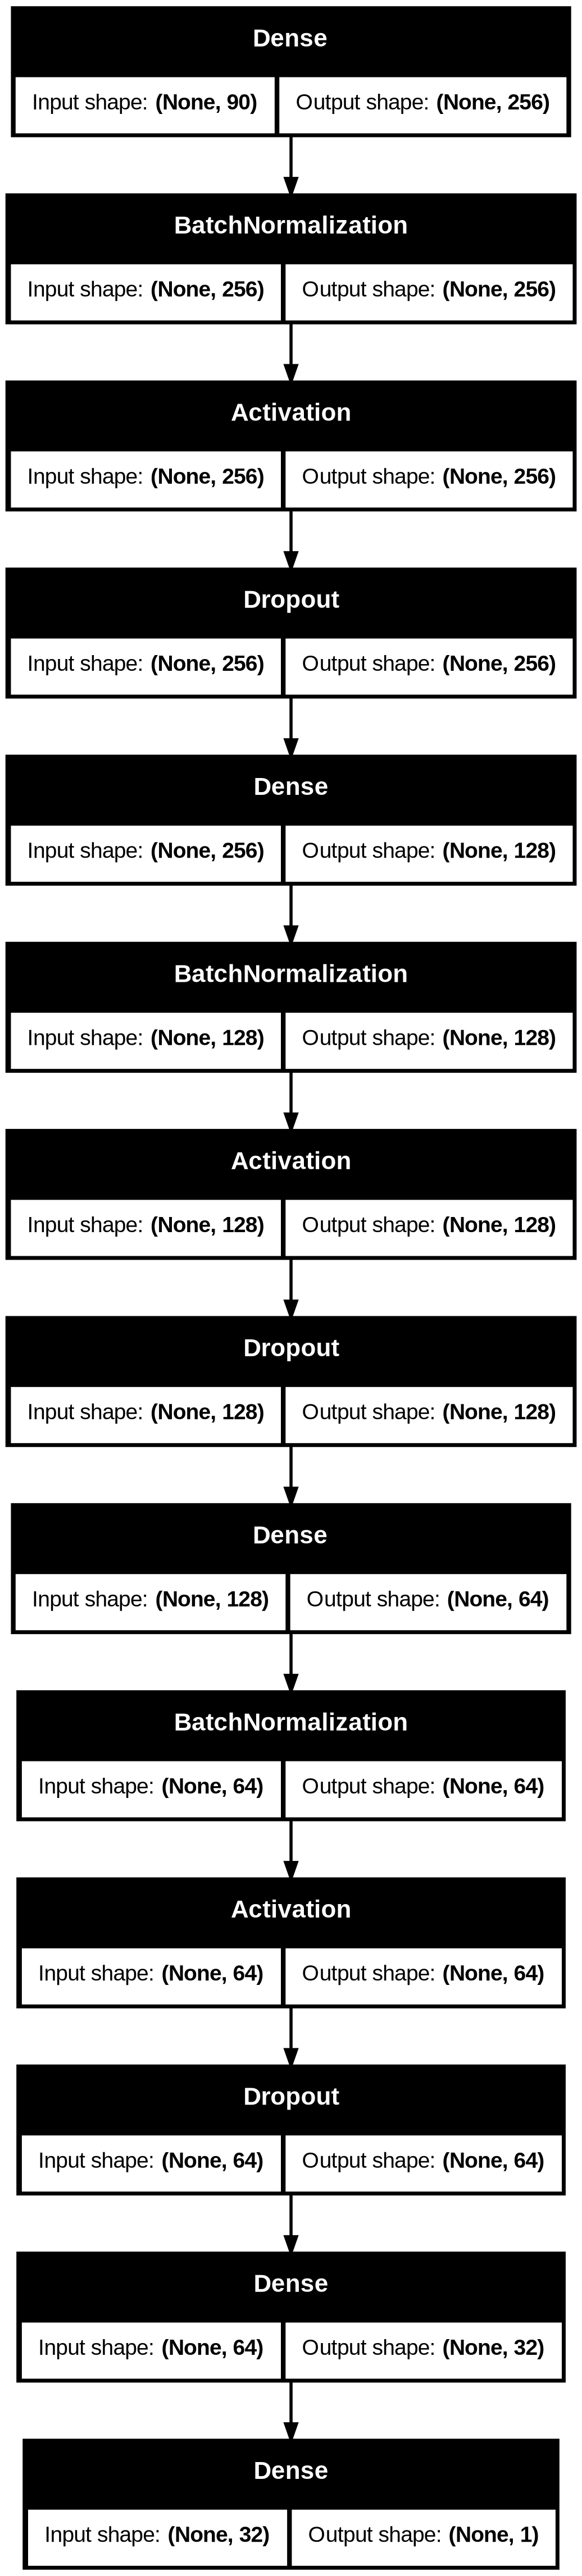

In [6]:
keras.utils.plot_model(model_seq, show_shapes=True,
                       to_file=os.path.join(DIR_FIGURAS, 'arq1_mlp_sequential.png'))

## 3. Arquitectura 2 — *Entity embeddings* + ruta lineal y bloques residuales (*Wide & Deep*)

### Esquema

```
 x_numerico (17 + 11 banderas)  x_contexto (14)   5 entradas categóricas (enteros)
        │            │                │            ESTRATO  MEDIDOR  MES  CL_TRAFO  CL_CIRC
        │            │                │               │        │      │      │        │
        │            │                │           Embedding (4, 3, 6, 7, 9) + Flatten
        │            │                │               └────────┴──┬───┴──────┴────────┘
        │            └──────────┬─────┴───────────────────────────┘
        │                  Concatenate (71)
        │                       │
        │            Dense 256 ─ BN ─ ReLU ─ Dropout 0,15
        │                       │
        │            ┌── Bloque residual 1: [Dense 256 ─ BN ─ ReLU ─ Dropout ─ Dense 256 ─ BN] + atajo ─ ReLU
        │            └── Bloque residual 2: [ídem]
        │                       │
        │               Dense 64 ─ ReLU
        │                       │
   Dense 1 (lineal)      Dense 1 (lineal)
   "ruta_lineal"         "ruta_profunda"
        └──────── Add ──────────┘
                   │
                kwh_dia
```

### Justificación

- ***Entity embeddings* en lugar de *one-hot*** (Guo y Berkhahn, 2016): cada clúster de transformador o circuito se proyecta a un vector denso aprendido, de modo que clústeres con comportamiento parecido queden cercanos. Esto permite compartir información entre los 15 + 21 grupos y es más eficiente que el *one-hot* cuando se cruzan con otras variables. La dimensión sigue la regla `min(10, 1,6·k^0,56)`; las categóricas de efecto pequeño (estrato, medidor; E5) quedan con 3–4 dimensiones.
- **Ruta lineal (*wide*)** (Cheng et al., 2016): la historia de consumo explica la mayor parte de la varianza con una relación casi lineal (E1, E2). Conectar directamente `x_numerico` a la salida con una capa lineal permite que el modelo arranque cerca de un modelo de persistencia y que la **ruta profunda aprenda solo la corrección** no lineal (interacciones con estrato, clúster, ceros previos, calendario).
- **Bloques residuales** (He et al., 2016): con atajos de identidad, la red puede tener más profundidad sin degradar el gradiente; si una capa no aporta, el bloque converge a la identidad.
- **Entradas separadas por bloque:** facilita la ablación del contexto de los catálogos (sección 0.4) sin redefinir la arquitectura y deja trazable qué información entra a cada ruta.

In [7]:
def bloque_residual(x, unidades, tasa_dropout, nombre):
    atajo = x
    h = layers.Dense(unidades, kernel_initializer='he_normal', name=f'{nombre}_densa_a')(x)
    h = layers.BatchNormalization(name=f'{nombre}_bn_a')(h)
    h = layers.Activation('relu', name=f'{nombre}_relu_a')(h)
    h = layers.Dropout(tasa_dropout, name=f'{nombre}_dropout')(h)
    h = layers.Dense(unidades, kernel_initializer='he_normal', name=f'{nombre}_densa_b')(h)
    h = layers.BatchNormalization(name=f'{nombre}_bn_b')(h)
    h = layers.Add(name=f'{nombre}_suma')([atajo, h])
    return layers.Activation('relu', name=f'{nombre}_relu_salida')(h)


def entradas_y_embeddings(categoricas):
    # Una entrada entera por categórica -> Embedding -> Flatten
    entradas, vectores = [], []
    for nombre, k in categoricas.items():
        inp = keras.Input(shape=(1,), dtype='int32', name=f'cat_{nombre.lower()}')
        emb = layers.Embedding(input_dim=k + 1, output_dim=dim_embedding(k),
                               name=f'emb_{nombre.lower()}')(inp)
        entradas.append(inp)
        vectores.append(layers.Flatten(name=f'flat_{nombre.lower()}')(emb))
    return entradas, vectores

In [8]:
# Entradas
in_num = keras.Input(shape=(len(NUM_TABULAR) + len(BANDERAS_NULO),), name='x_numerico')
in_ctx = keras.Input(shape=(len(CTX),), name='x_contexto')
in_cat, emb_cat = entradas_y_embeddings(CATEGORICAS)

# Ruta lineal (wide): persistencia sobre la historia de consumo
salida_lineal = layers.Dense(1, activation='linear', name='ruta_lineal')(in_num)

# Ruta profunda (deep)
x = layers.Concatenate(name='concat_deep')([in_num, in_ctx] + emb_cat)
x = layers.Dense(256, kernel_initializer='he_normal', name='densa_entrada')(x)
x = layers.BatchNormalization(name='bn_entrada')(x)
x = layers.Activation('relu', name='relu_entrada')(x)
x = layers.Dropout(0.15, name='dropout_entrada')(x)
x = bloque_residual(x, 256, 0.15, 'res1')
x = bloque_residual(x, 256, 0.15, 'res2')
x = layers.Dense(64, activation='relu', kernel_initializer='he_normal', name='densa_64')(x)
salida_profunda = layers.Dense(1, activation='linear', name='ruta_profunda')(x)

# Salida: suma de la ruta lineal y la corrección no lineal
salida = layers.Add(name='kwh_dia')([salida_lineal, salida_profunda])

model_wd = keras.Model(inputs=[in_num, in_ctx] + in_cat, outputs=salida,
                       name='Arq2_Embeddings_WideDeep_Residual')

model_wd.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss=keras.losses.Huber(delta=1.0),
    metrics=[keras.metrics.MeanAbsoluteError(name='mae'),
             keras.metrics.RootMeanSquaredError(name='rmse')],
)

In [9]:
model_wd.summary()

Model: "Arq2_Embeddings_WideDeep_Residual"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ cat_estrato_sector  │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cat_tipo_medidor    │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cat_mes_consumo     │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cat_cluster_transf… │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cat_cluster_circui… │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ emb_estrato_sector  │ (None, 1, 4)      │         28 │ cat_estrato_sect… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ emb_tipo_medidor    │ (None, 1, 3)      │         15 │ cat_tipo_medidor… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ emb_mes_consumo     │ (None, 1, 6)      │         78 │ cat_mes_consumo[… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ emb_cluster_transf… │ (None, 1, 7)      │        112 │ cat_cluster_tran… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ emb_cluster_circui… │ (None, 1, 9)      │        198 │ cat_cluster_circ… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ x_numerico          │ (None, 28)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ x_contexto          │ (None, 14)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flat_estrato_sector │ (None, 4)         │          0 │ emb_estrato_sect… │
│ (Flatten)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flat_tipo_medidor   │ (None, 3)         │          0 │ emb_tipo_medidor… │
│ (Flatten)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flat_mes_consumo    │ (None, 6)         │          0 │ emb_mes_consumo[… │
│ (Flatten)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flat_cluster_trans… │ (None, 7)         │          0 │ emb_cluster_tran… │
│ (Flatten)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flat_cluster_circu… │ (None, 9)         │          0 │ emb_cluster_circ

 Total params: 303,693 (1.16 MB)

 Trainable params: 301,133 (1.15 MB)

 Non-trainable params: 2,560 (10.00 KB)

In [10]:
keras.utils.plot_model(model_wd, show_shapes=True,
                       to_file=os.path.join(DIR_FIGURAS, 'arq2_embeddings_wide_deep.png'))

## 4. Arquitectura 3 — Híbrida Conv1D-LSTM con salida de dos partes (probabilidad de cero × magnitud)

### Esquema

```
 secuencia (12 meses × 2 canales)        x_estatico (7 + 14)        5 categóricas
 [log1p kWh/día escalado, observado]     facturación + contexto     Embedding + Flatten
            │                                     │                        │
 Conv1D 32, k=3, causal ─ ReLU                    └────── Concatenate ─────┘
            │                                                 │
 LSTM 64 (return_sequences) ─ Dropout 0,2              Dense 64 ─ BN ─ ReLU
            │                                                 │
 LSTM 32                                                      │
            └──────────────────── Concatenate ────────────────┘
                                      │
                       Dense 128 ─ ReLU ─ Dropout 0,2
                                      │
                               Dense 64 ─ ReLU
                          ┌───────────┴───────────┐
               Dense 1 sigmoide            Dense 1 softplus
                 "prob_cero"               "kwh_si_consume"
                      │                           │
            Rescaling (1 − p)                     │
                      └──────── Multiply ─────────┘
                                   │
                                kwh_dia  =  (1 − p) · μ⁺
```

### Justificación

- **Secuencia en lugar de rezagos sueltos:** los rezagos y medias móviles (cuaderno 2) son resúmenes fijos de la serie del usuario. La arquitectura 3 recibe los **12 meses previos completos** y deja que la red aprenda qué resumen es útil. Esto sigue la línea de la literatura revisada (CNN-LSTM de Kim y Cho, 2019; variantes LSTM en §1.2 del documento). Las variables que se derivan de la serie (`LAG*`, `MM*`, `STD6`, `CV6`, `TENDENCIA`, `ESTACIONAL`, `PCT_CEROS_PREVIOS`, `MESES_HIST_12`) no se repiten en la rama estática.
- **Canal `OBSERVADO`:** distingue «mes sin dato» (historia corta, E4) de «mes con consumo cero», que son situaciones distintas para el pronóstico.
- **Conv1D causal (k = 3):** extrae patrones locales trimestrales (subidas, caídas, rachas de ceros) sin mirar meses posteriores dentro de la ventana.
- **LSTM apiladas 64 → 32:** capturan la dependencia de largo plazo, incluido el mismo mes del año anterior (t−12), relevante porque `KWH_DIA_LAG12` mantiene ρ = 0,76 (E1).
- **Rama estática:** calendario de la factura (días facturados, fines de semana, festivos, retraso), meses desde el cambio de medidor y el contexto del transformador y circuito, más los *embeddings* de la arquitectura 2.
- **Salida en dos partes (modelo *hurdle*):** los meses en cero con historia activa no se pueden anticipar con un promedio (E8). Se separa la **probabilidad de consumo cero** (`prob_cero`, sigmoide, entrenada con entropía cruzada binaria sobre `KWH_DIA == 0`) de la **magnitud si hay consumo** (μ⁺, `softplus` para garantizar valores ≥ 0). La predicción final es el valor esperado `(1 − p) · μ⁺`, entrenada con Huber. La salida `prob_cero` además permite interpretar el riesgo de desocupación o suspensión.

In [11]:
NUM_ESTATICAS_SEQ = ['MESES_DESDE_CAMBIO', 'DIAS_FACTURADOS', 'DIA_LECTURA',
                     'DIAS_FIN_SEMANA', 'DIAS_FESTIVOS', 'RETRASO_FACTURA']
BANDERAS_ESTATICAS_SEQ = ['NULO_MESES_DESDE_CAMBIO']
N_ESTATICAS = len(NUM_ESTATICAS_SEQ) + len(BANDERAS_ESTATICAS_SEQ) + len(CTX)

# Entradas
in_seq = keras.Input(shape=(N_MESES_SECUENCIA, len(CANALES_SECUENCIA)), name='secuencia_consumo')
in_est = keras.Input(shape=(N_ESTATICAS,), name='x_estatico')
in_cat3, emb_cat3 = entradas_y_embeddings(CATEGORICAS)

# Rama secuencial: Conv1D causal + LSTM apiladas
s = layers.Conv1D(32, kernel_size=3, padding='causal', activation='relu', name='conv1d_causal')(in_seq)
s = layers.LSTM(64, return_sequences=True, name='lstm_64')(s)
s = layers.Dropout(0.20, name='dropout_lstm')(s)
s = layers.LSTM(32, name='lstm_32')(s)

# Rama estática
e = layers.Concatenate(name='concat_estatico')([in_est] + emb_cat3)
e = layers.Dense(64, kernel_initializer='he_normal', name='densa_estatica')(e)
e = layers.BatchNormalization(name='bn_estatica')(e)
e = layers.Activation('relu', name='relu_estatica')(e)

# Fusión
f = layers.Concatenate(name='fusion')([s, e])
f = layers.Dense(128, activation='relu', kernel_initializer='he_normal', name='densa_fusion_128')(f)
f = layers.Dropout(0.20, name='dropout_fusion')(f)
f = layers.Dense(64, activation='relu', kernel_initializer='he_normal', name='densa_fusion_64')(f)

# Cabezas: probabilidad de cero y magnitud si hay consumo
p_cero = layers.Dense(1, activation='sigmoid', name='prob_cero')(f)
mu_pos = layers.Dense(1, activation='softplus', name='kwh_si_consume')(f)
p_consumo = layers.Rescaling(scale=-1.0, offset=1.0, name='prob_consumo')(p_cero)   # 1 - p
kwh_dia = layers.Multiply(name='kwh_dia')([p_consumo, mu_pos])                     # (1 - p) * mu+

model_hib = keras.Model(
    inputs=[in_seq, in_est] + in_cat3,
    outputs={'kwh_dia': kwh_dia, 'prob_cero': p_cero},
    name='Arq3_Conv1D_LSTM_Hurdle',
)

model_hib.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss={'kwh_dia': keras.losses.Huber(delta=1.0),
          'prob_cero': keras.losses.BinaryCrossentropy()},
    loss_weights={'kwh_dia': 1.0, 'prob_cero': 0.3},
    metrics={'kwh_dia': [keras.metrics.MeanAbsoluteError(name='mae'),
                         keras.metrics.RootMeanSquaredError(name='rmse')],
             'prob_cero': [keras.metrics.AUC(name='auc')]},
)

In [12]:
model_hib.summary()

Model: "Arq3_Conv1D_LSTM_Hurdle"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ cat_estrato_sector  │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cat_tipo_medidor    │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cat_mes_consumo     │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cat_cluster_transf… │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cat_cluster_circui… │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ emb_estrato_sector  │ (None, 1, 4)      │         28 │ cat_estrato_sect… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ emb_tipo_medidor    │ (None, 1, 3)      │         15 │ cat_tipo_medidor… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ emb_mes_consumo     │ (None, 1, 6)      │         78 │ cat_mes_consumo[… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ emb_cluster_transf… │ (None, 1, 7)      │        112 │ cat_cluster_tran… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ emb_cluster_circui… │ (None, 1, 9)      │        198 │ cat_cluster_circ… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ secuencia_consumo   │ (None, 12, 2)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ x_estatico          │ (None, 21)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flat_estrato_sector │ (None, 4)         │          0 │ emb_estrato_sect… │
│ (Flatten)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flat_tipo_medidor   │ (None, 3)         │          0 │ emb_tipo_medidor… │
│ (Flatten)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flat_mes_consumo    │ (None, 6)         │          0 │ emb_mes_consumo[… │
│ (Flatten)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flat_cluster_trans… │ (None, 7)         │          0 │ emb_cluster_tran… │
│ (Flatten)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flat_cluster_circu… │ (None, 9)         │          0 │ emb_cluster_circ

 Total params: 62,225 (243.07 KB)

 Trainable params: 62,097 (242.57 KB)

 Non-trainable params: 128 (512.00 B)

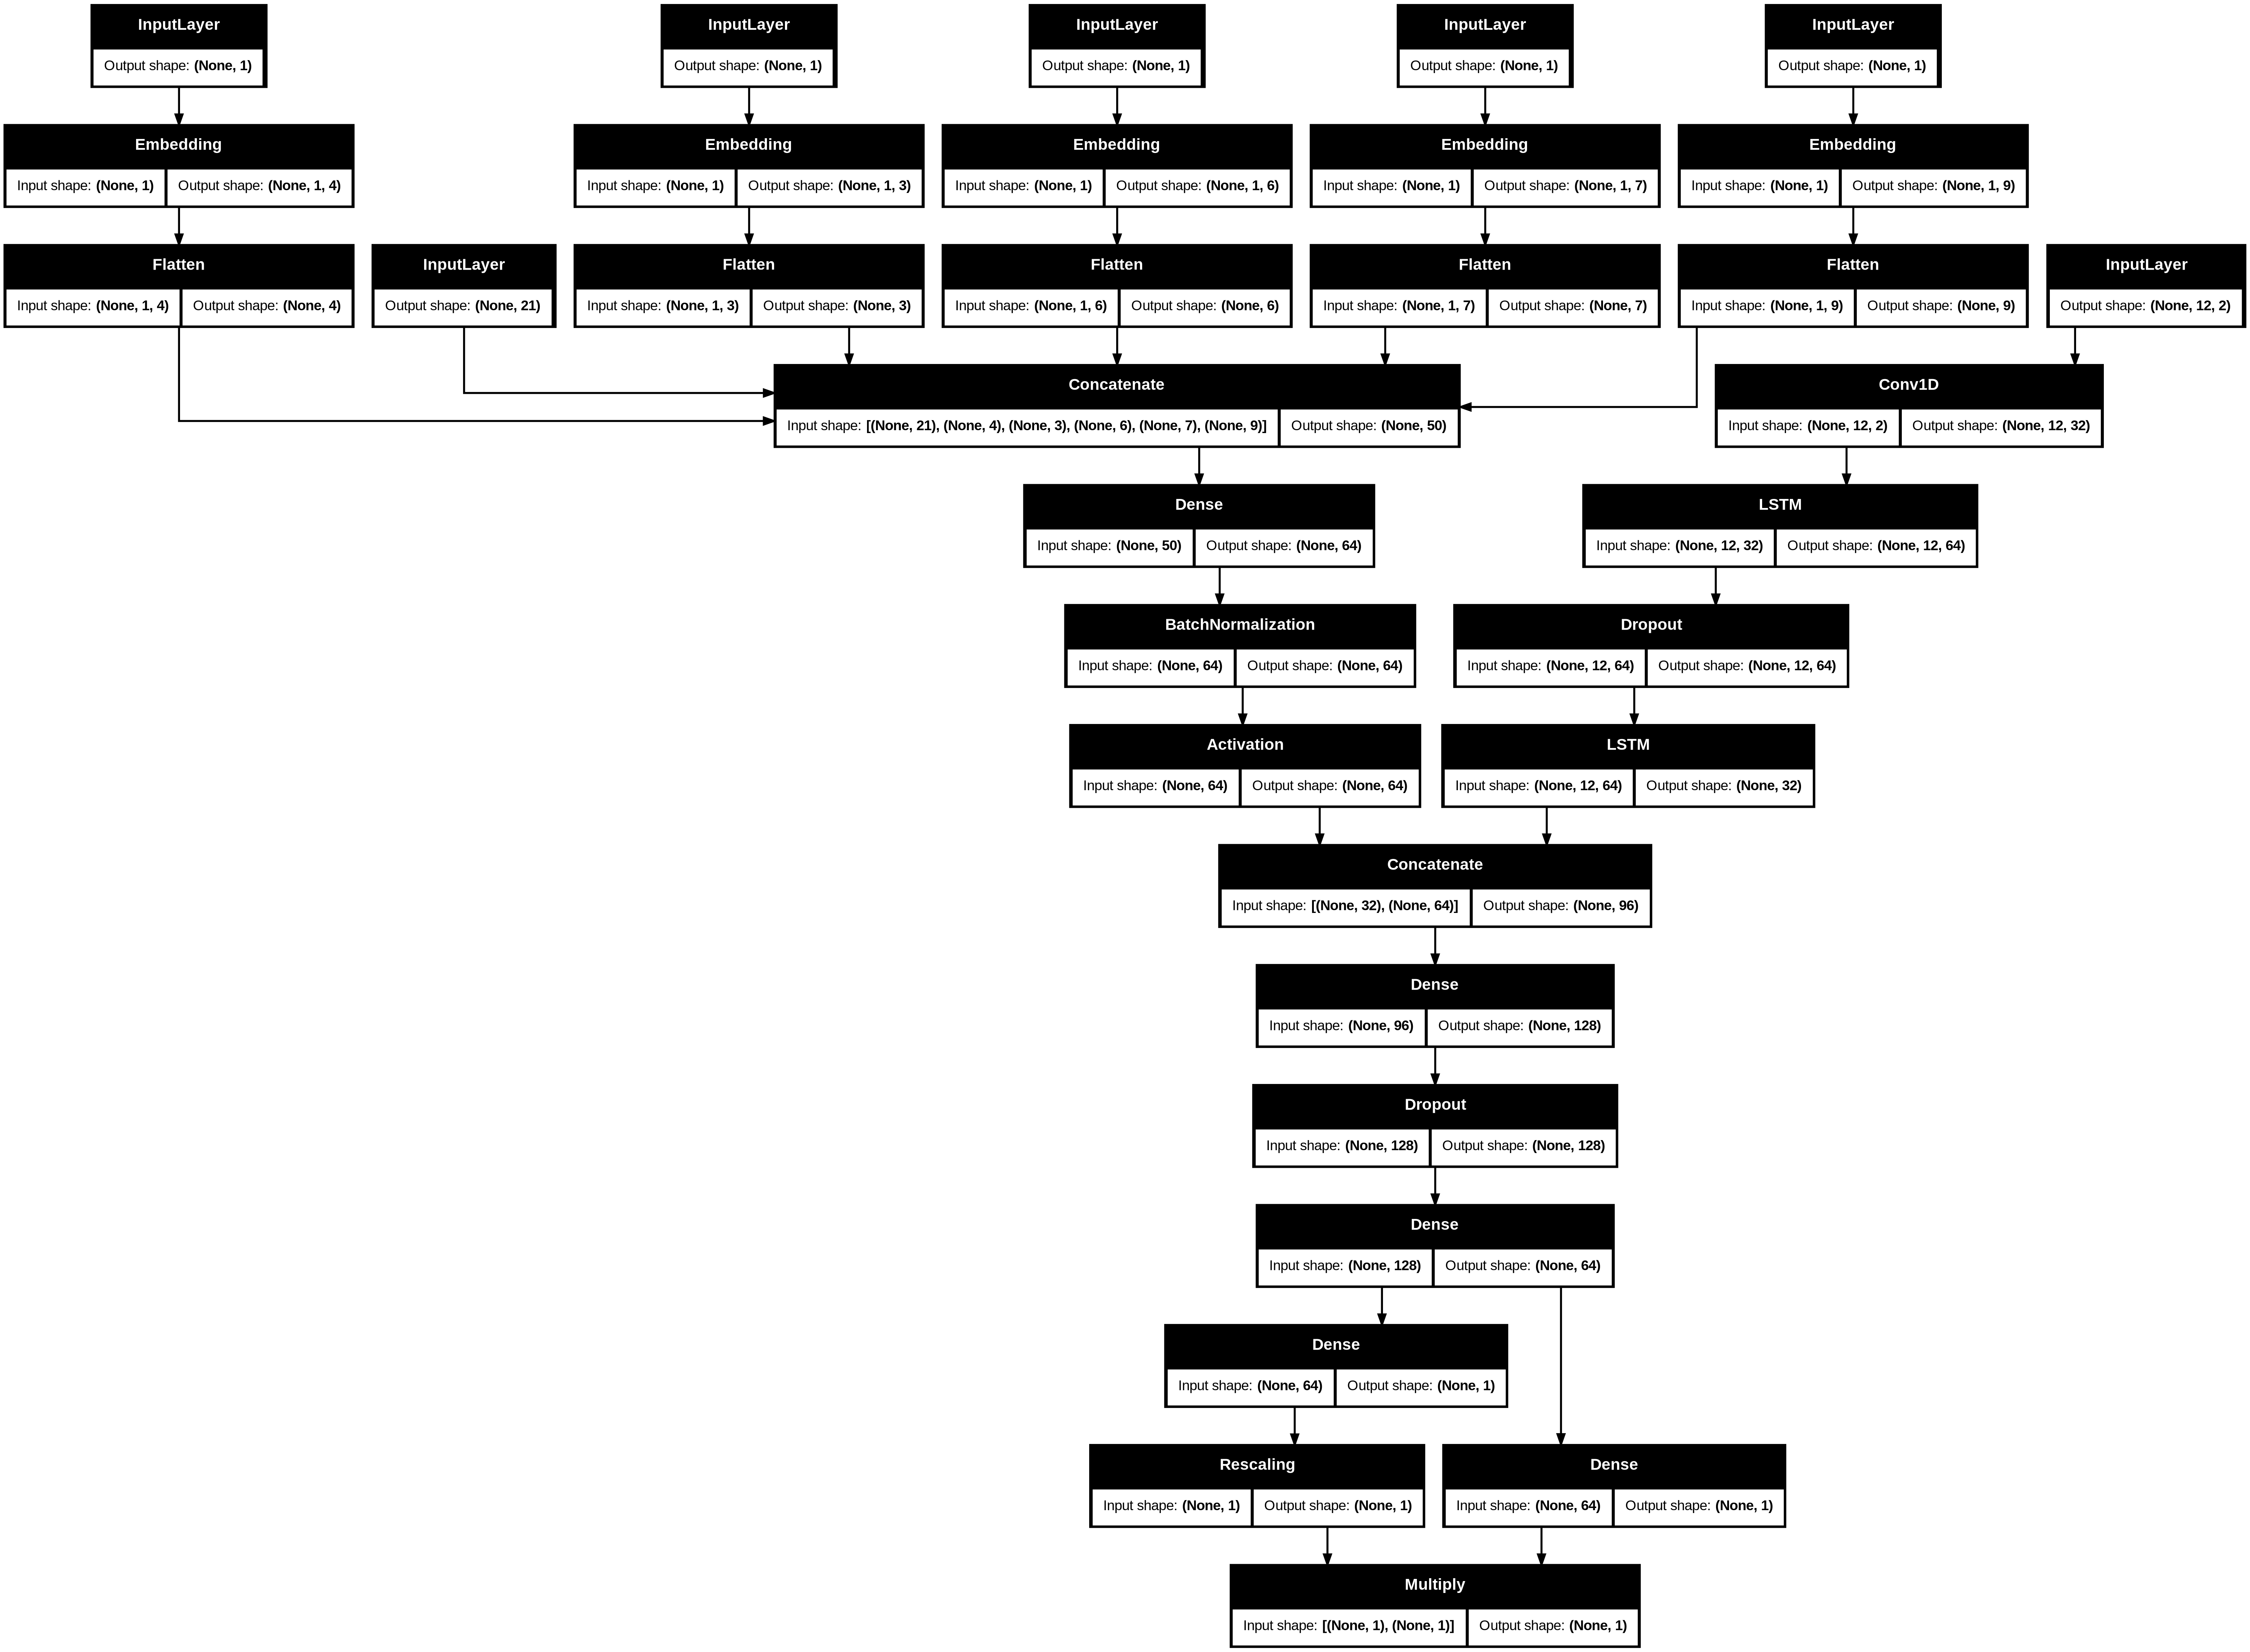

In [13]:
keras.utils.plot_model(model_hib, show_shapes=True,
                       to_file=os.path.join(DIR_FIGURAS, 'arq3_conv1d_lstm_hurdle.png'))

## 5. Comparación de las propuestas y pendientes para el entrenamiento

In [14]:
def resumen_modelo(modelo, api, info_historia, info_categoricas, salidas):
    entrenables = int(sum(np.prod(w.shape) for w in modelo.trainable_weights))
    no_entrenables = int(sum(np.prod(w.shape) for w in modelo.non_trainable_weights))
    return {
        'Modelo': modelo.name,
        'API': api,
        'Entradas': len(modelo.inputs),
        'Capas': len(modelo.layers),
        'Parámetros entrenables': entrenables,
        'Parámetros no entrenables': no_entrenables,
        'Historia de consumo': info_historia,
        'Categóricas': info_categoricas,
        'Salidas': salidas,
    }

comparacion = pd.DataFrame([
    resumen_modelo(model_seq, 'Sequential', 'Vector (17 + 11 banderas)', 'One-hot + cíclico', 'kwh_dia'),
    resumen_modelo(model_wd, 'Funcional', 'Vector (17 + 11 banderas)', 'Embeddings', 'kwh_dia (lineal + profunda)'),
    resumen_modelo(model_hib, 'Funcional', 'Secuencia 12 × 2', 'Embeddings', 'kwh_dia, prob_cero'),
]).set_index('Modelo')
comparacion

,API,Entradas,Capas,Parámetros entrenables,Parámetros no entrenables,Historia de consumo,Categóricas,Salidas
Modelo,,,,,,,,
Arq1_MLP_Sequential,Sequential,1,14,67457,896,Vector (17 + 11 banderas),One-hot + cíclico,kwh_dia
Arq2_Embeddings_WideDeep_Residual,Funcional,7,42,301133,2560,Vector (17 + 11 banderas),Embeddings,kwh_dia (lineal + profunda)
Arq3_Conv1D_LSTM_Hurdle,Funcional,7,33,62097,128,Secuencia 12 × 2,Embeddings,"kwh_dia, prob_cero"


### Pendientes para el cuaderno de entrenamiento

1. Materializar las matrices de entrada: unir `dataset_modelo_prep` con los catálogos del cuaderno 3 (por `COD_TRANSFORMADOR` y `COD_CIRCUITO_LINEA`), aplicar `log1p`/`RobustScaler` ajustados con el 70 % de entrenamiento y generar las banderas de nulo.
2. Construir el tensor de secuencia (12 × 2) por usuario-mes para la arquitectura 3, con ventanas que excluyan el mes objetivo.
3. Entrenar con generadores por lotes (`tf.data` o `keras.utils.PyDataset`) dado el volumen (~76 millones de registros de entrenamiento).
4. Ajustar en el conjunto de prueba: tasa de aprendizaje, δ de Huber, *dropout*, tamaño de lote y `loss_weights` de la arquitectura 3.
5. Ablación del contexto de los catálogos (con y sin `x_contexto`) en la arquitectura 2.
6. Evaluar en validación con MAE, RMSE y R² frente a la línea base semestral (`BENCH_KWH_DIA`), aplicando el mismo filtro de extremos a modelo y línea base.

### Referencias

- Cheng, H.-T. et al. (2016). *Wide & Deep Learning for Recommender Systems*. DLRS 2016.
- Guo, C. y Berkhahn, F. (2016). *Entity Embeddings of Categorical Variables*. arXiv:1604.06737.
- He, K., Zhang, X., Ren, S. y Sun, J. (2016). *Deep Residual Learning for Image Recognition*. CVPR.
- Howard, J. y Gugger, S. (2020). *Deep Learning for Coders with fastai and PyTorch*. O'Reilly.
- Huber, P. J. (1964). Robust Estimation of a Location Parameter. *Annals of Mathematical Statistics*, 35(1).
- Kim, T.-Y. y Cho, S.-B. (2019). Predicting residential energy consumption using CNN-LSTM neural networks. *Energy*, 182.
- Mullahy, J. (1986). Specification and testing of some modified count data models. *Journal of Econometrics*, 33(3).